<a href="https://colab.research.google.com/github/mohangowda2607-source/Cohort-4-Mohan-Kumar-S/blob/main/Mini_Project_C4_Mohan_285561.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Mini Project — Cohort 4



In [1]:
INSURANCE_CSV = "/content/insurance2 (1).csv"
MA_PDF        = "/content/M&A_Due_Diligence_Playbook.pdf"

---
# PART A — Machine Learning: Insurance Claim Prediction

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

data = pd.read_csv(INSURANCE_CSV)

In [3]:
data.head()      # 1. first 5 records

,age,sex,bmi,children,smoker,region,charges,insuranceclaim
0,19,0,27.900,0,1,3,16884.92400,1
1,18,1,33.770,1,0,2,1725.55230,1
2,28,1,33.000,3,0,2,4449.46200,0
3,33,1,22.705,0,0,1,21984.47061,0
4,32,1,28.880,0,0,1,3866.85520,1


In [4]:
data.tail()      # 2. last 5 records

,age,sex,bmi,children,smoker,region,charges,insuranceclaim
1333,50,1,30.97,3,0,1,10600.5483,0
1334,18,0,31.92,0,0,0,2205.9808,1
1335,18,0,36.85,0,0,2,1629.8335,1
1336,21,0,25.80,0,0,3,2007.9450,0
1337,61,0,29.07,0,1,1,29141.3603,1


In [5]:
print("Rows, columns:", data.shape)          # 3. number of rows and columns
print("Columns:", list(data.columns))        # 4. all column names

Rows, columns: (1338, 8)
Columns: ['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges', 'insuranceclaim']


In [6]:
data.dtypes      # 5. data types

,0
age,int64
sex,int64
bmi,float64
children,int64
smoker,int64
region,int64
charges,float64
insuranceclaim,int64


In [7]:
data.isnull().sum()      # 6. missing values per column

,0
age,0
sex,0
bmi,0
children,0
smoker,0
region,0
charges,0
insuranceclaim,0


In [8]:
TARGET = "insuranceclaim"

summary = pd.DataFrame({
    "dtype": data.dtypes.astype(str),
    "distinct_values": data.nunique(),
    "example_values": [sorted(data[c].dropna().unique())[:6] for c in data.columns],
})
summary

,dtype,distinct_values,example_values
age,int64,47,"[18, 19, 20, 21, 22, 23]"
sex,int64,2,"[0, 1]"
bmi,float64,548,"[15.96, 16.815, 17.195, 17.29, 17.385, 17.4]"
children,int64,6,"[0, 1, 2, 3, 4, 5]"
smoker,int64,2,"[0, 1]"
region,int64,4,"[0, 1, 2, 3]"
charges,float64,1337,"[1121.8739, 1131.5066, 1135.9407, 1136.3994, 1..."
insuranceclaim,int64,2,"[0, 1]"


In [9]:
# Decide numerical vs categorical from the table above
categorical_cols = ["sex", "smoker", "region"]            # labels/codes, not quantities
numerical_cols   = ["age", "bmi", "children", "charges"]  # measured or counted quantities

print("Numerical  :", numerical_cols)
print("Categorical:", categorical_cols, "(and the target)")
print("Target     :", TARGET)

counts = data[TARGET].value_counts()
share  = data[TARGET].value_counts(normalize=True).mul(100).round(1)
print("\nTarget distribution:")
print(pd.DataFrame({"count": counts, "percent": share}))
ratio = counts.max() / counts.min()
print(f"\nMajority : minority ratio = {ratio:.2f} : 1")

Numerical  : ['age', 'bmi', 'children', 'charges']
Categorical: ['sex', 'smoker', 'region'] (and the target)
Target     : insuranceclaim

Target distribution:
                count  percent
insuranceclaim                
1                 783     58.5
0                 555     41.5

Majority : minority ratio = 1.41 : 1


**Answer**

1. **Numerical variables:** `age`, `bmi`, `children`, `charges`. (`children` is a count; it is numeric but discrete.)
2. **Categorical variables:** `sex`, `smoker`, `region`, and the target `insuranceclaim`. If the table above shows them stored as integers, they are still categories — the numbers are codes, not amounts.
3. **Target variable:** `insuranceclaim` (1 = claim, 0 = no claim).
4. **Is the target balanced?** Reasonably. 783 customers (58.5%) have a claim and 555 (41.5%) do not, a ratio of 1.41 : 1. That is a mild imbalance that needs no resampling, but it is the reason the split below uses `stratify=y` and the evaluation reports precision and recall as well as accuracy.

Also from Task 1: 1,338 rows and 8 columns, no missing values, and every column is stored as a number — `sex`, `smoker` and `region` arrive already coded as integers.

## Task 2. Exploratory data analysis
### Univariate analysis: Age, BMI, Charges, Insurance claims

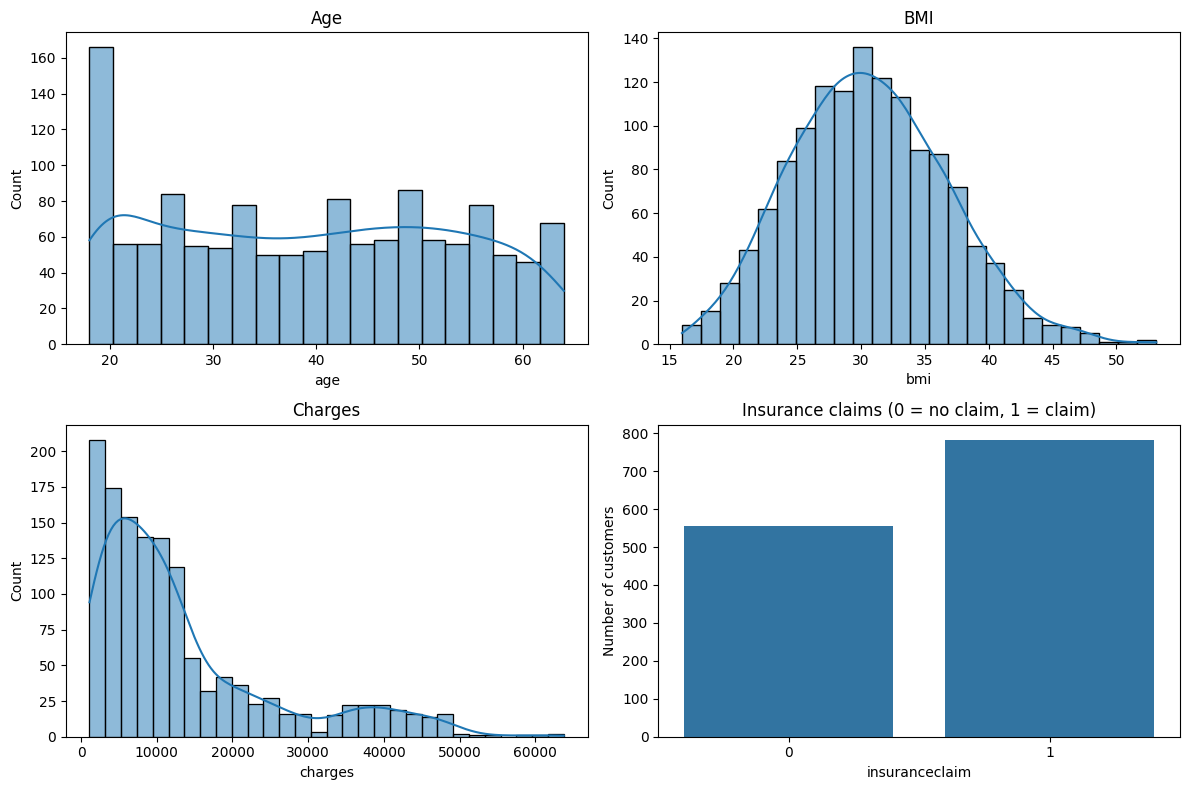

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

sns.histplot(data["age"], bins=20, kde=True, ax=axes[0, 0])
axes[0, 0].set_title("Age")

sns.histplot(data["bmi"], bins=25, kde=True, ax=axes[0, 1])
axes[0, 1].set_title("BMI")

sns.histplot(data["charges"], bins=30, kde=True, ax=axes[1, 0])
axes[1, 0].set_title("Charges")

sns.countplot(x=data[TARGET], ax=axes[1, 1])
axes[1, 1].set_title("Insurance claims (0 = no claim, 1 = claim)")
axes[1, 1].set_ylabel("Number of customers")

plt.tight_layout()
plt.show()

In [11]:
data[["age", "bmi", "charges"]].describe()     # mean, std, quartiles (session 1)

,age,bmi,charges
count,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,13270.422265
std,14.049960,6.098187,12110.011237
min,18.000000,15.960000,1121.873900
25%,27.000000,26.296250,4740.287150
50%,39.000000,30.400000,9382.033000
75%,51.000000,34.693750,16639.912515
max,64.000000,53.130000,63770.428010


In [12]:
# Skewness tells you whether a histogram has a long tail (0 = symmetric, > 1 = strongly right-skewed)
data[["age", "bmi", "charges"]].skew().round(2)

,0
age,0.06
bmi,0.28
charges,1.52


**Answer — what the charts show**

- **Age:** 18 to 64, mean 39.2, spread fairly evenly across the range (skew 0.06) with a taller bar at the youngest ages.
- **BMI:** close to a bell shape, mean 30.7 and median 30.4 (skew 0.28). Just over half of the customers (52.7%) are above 30.
- **Charges:** strongly right-skewed (skew 1.52). The median is 9,382 but the mean is 13,270 and the maximum is 63,770, so a small group of customers has very high charges. This is the wide range raised in class and the reason for scaling in Task 3.
- **Insurance claims:** 783 claims against 555 non-claims, the 58.5% / 41.5% balance from Task 1.

From the heat map below, the columns most related to a claim are `children` (−0.41: more children, fewer claims), `bmi` (+0.38), `smoker` (+0.33) and `charges` (+0.31). `sex` and `region` are close to zero.

Heat Map - Additional

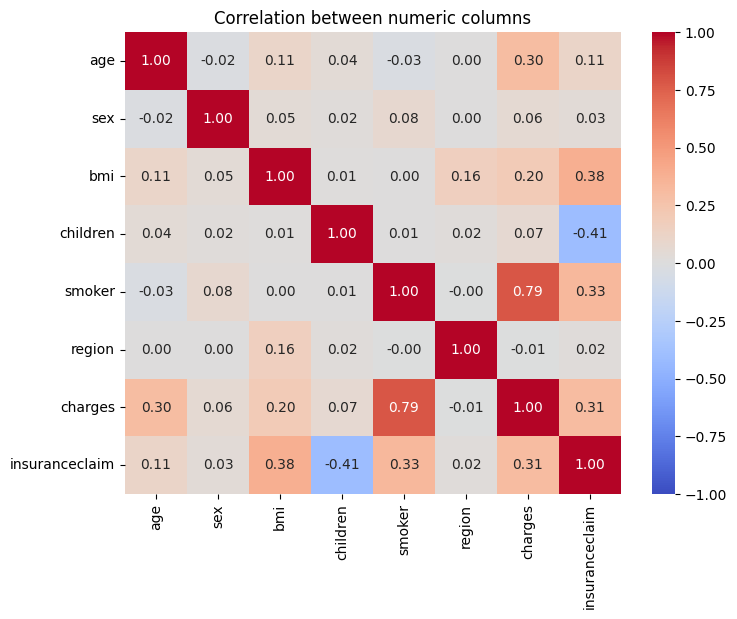

In [13]:
plt.figure(figsize=(8, 6))
sns.heatmap(data.corr(numeric_only=True), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation between numeric columns")
plt.show()

## Task 3. Data preprocessing

In [14]:
# 1. Separate independent variables and the target variable
X = data.drop([TARGET], axis=1)    # input independent columns
y = data[TARGET]                   # output dependent column
print(X.shape, y.shape)

(1338, 7) (1338,)


In [15]:
# 3. Split FIRST, so that nothing is learned from the test rows
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,      # 20% testing, 80% training
    random_state=42,     # same split on every run
    stratify=y           # keep the claim / no-claim proportion equal in both sets
)
print("Training rows:", X_train.shape[0])
print("Testing rows :", X_test.shape[0])

Training rows: 1070
Testing rows : 268


In [16]:
# 2 + 4. Encoding and scaling, defined once and LEARNED FROM THE TRAINING SET ONLY
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

preprocess = ColumnTransformer(
    transformers=[
        # region has no natural order, so one-hot encode it; sex and smoker become a single 0/1 column each
        ("cat", OneHotEncoder(drop="if_binary", handle_unknown="ignore"), categorical_cols),
        # age, bmi, children and charges are on very different ranges, so standardise them
        ("num", StandardScaler(), numerical_cols),
    ]
)

X_train_prepared = preprocess.fit_transform(X_train)   # fit = learn categories, means and standard deviations from TRAIN
X_test_prepared  = preprocess.transform(X_test)        # transform only = reuse what was learned; nothing is learned from TEST

feature_names = preprocess.get_feature_names_out()
pd.DataFrame(X_train_prepared, columns=feature_names).head()

,cat__sex_1,cat__smoker_1,cat__region_0,cat__region_1,cat__region_2,cat__region_3,num__age,num__bmi,num__children,num__charges
0,0.0,0.0,0.0,0.0,1.0,0.0,-0.363261,-0.485391,-0.895549,-0.728967
1,1.0,1.0,0.0,0.0,1.0,0.0,0.136523,0.844929,-0.067340,2.307595
2,1.0,1.0,0.0,0.0,1.0,0.0,-1.505623,0.170657,0.760869,1.802004
3,1.0,0.0,1.0,0.0,0.0,0.0,-1.220032,-1.772637,1.589077,-0.763665
4,0.0,1.0,0.0,0.0,1.0,0.0,-1.505623,1.027165,-0.895549,1.958353


**Why these choices**

- **Encoding.** `sex` and `smoker` have two categories, so one 0/1 column each is enough. `region` has several categories with no order; leaving it as 0, 1, 2, 3 (or label-encoding it) would tell the model that region 3 is "more" than region 1. One-hot encoding avoids that. scikit-learn's own documentation says `LabelEncoder` is for the target `y`, not for input columns.
- **Scaling.** `charges` runs into the tens of thousands while `bmi` and `age` stay under 100. Logistic regression is fitted by gradient-based optimisation, which converges better and treats features more evenly when they are on a similar scale.
- **5. No data leakage.** The split happens before any transformation, and `fit_transform` is called on the training set only.

**Answer — why learn preprocessing from the training dataset rather than the complete dataset?**

The test set stands in for future customers the model has never seen. If the scaler's mean and standard deviation (or an encoder's categories, or an imputer's fill value) are computed on the complete dataset, information about the test rows flows into training. That is data leakage: the test score becomes optimistic and no longer estimates real-world performance. In production the same rule applies — a new customer is transformed with the statistics learned at training time, so evaluation must follow the same procedure.

## Task 4. Build machine learning models

In [17]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)     # max_iter raised to avoid the convergence warning seen in class

# 1. Train the model
model.fit(X_train_prepared, y_train)

LogisticRegression(max_iter=1000)

In [18]:
# 2. Generate predictions
predictions = model.predict(X_test_prepared)
predictions[:10]

array([1, 1, 0, 1, 1, 0, 1, 0, 1, 0])

In [19]:
# 3. Generate prediction probabilities
probabilities = model.predict_proba(X_test_prepared)[:, 1]     # probability of class 1 (claim)

pd.DataFrame({
    "actual": y_test.values[:10],
    "predicted": predictions[:10],
    "probability_of_claim": probabilities[:10].round(3),
})

,actual,predicted,probability_of_claim
0,1,1,0.999
1,1,1,0.611
2,0,0,0.057
3,1,1,0.979
4,1,1,1.000
5,0,0,0.292
6,1,1,0.972
7,0,0,0.195
8,1,1,0.776
9,1,0,0.435


In [20]:
# 4. Evaluate the model
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report,
                             ConfusionMatrixDisplay)

print("Accuracy :", round(accuracy_score(y_test, predictions), 4))
print("Precision:", round(precision_score(y_test, predictions), 4))   # of predicted claims, how many were real
print("Recall   :", round(recall_score(y_test, predictions), 4))      # of real claims, how many were caught
print("F1 score :", round(f1_score(y_test, predictions), 4))
print("ROC AUC  :", round(roc_auc_score(y_test, probabilities), 4))
print()
print(classification_report(y_test, predictions, target_names=["no claim", "claim"]))

Accuracy : 0.8582
Precision: 0.879
Recall   : 0.879
F1 score : 0.879
ROC AUC  : 0.9033

              precision    recall  f1-score   support

    no claim       0.83      0.83      0.83       111
       claim       0.88      0.88      0.88       157

    accuracy                           0.86       268
   macro avg       0.85      0.85      0.85       268
weighted avg       0.86      0.86      0.86       268



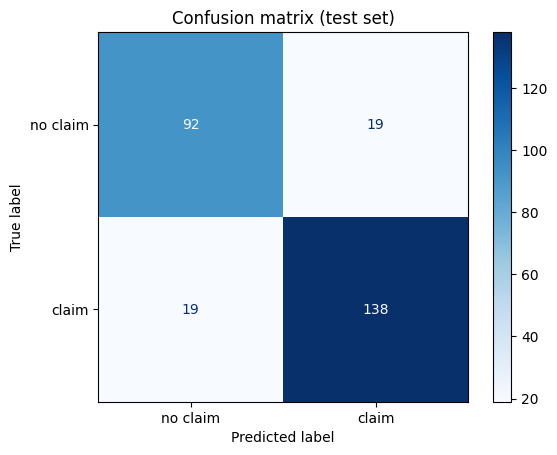

True negatives 92 | False positives 19 | False negatives 19 | True positives 138


In [21]:
cm = confusion_matrix(y_test, predictions)
ConfusionMatrixDisplay(cm, display_labels=["no claim", "claim"]).plot(cmap="Blues")
plt.title("Confusion matrix (test set)")
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"True negatives {tn} | False positives {fp} | False negatives {fn} | True positives {tp}")

In [22]:
# Which features push the prediction towards a claim? (positive = more likely to claim)
pd.Series(model.coef_[0], index=feature_names).sort_values()

,0
num__children,-1.731832
cat__region_1,-0.158621
cat__region_2,-0.142806
cat__region_3,0.046836
cat__sex_1,0.187260
cat__region_0,0.214254
num__age,0.269595
num__charges,0.319795
num__bmi,1.543205
cat__smoker_1,3.369951


**Answer — reading the evaluation** (figures from `random_state=42`; they will match if you keep that value)

- **Accuracy 85.8%** on the 268 test customers, with ROC AUC 0.90. By the instructor's rule of thumb, above 70–75% is worth considering and above 85% is good to deploy.
- **Precision 0.879 and recall 0.879** for the claim class. The confusion matrix has 138 true positives, 92 true negatives, 19 false positives and 19 false negatives.
- A false negative here is a customer predicted as "no claim" who then claims, which is the costly miss discussed in class, so recall is the metric to watch. The model misses 19 of 157 real claims.
- **What drives the prediction:** being a smoker (+3.37) and a higher BMI (+1.54) push most strongly towards a claim; more children (−1.73) pushes away from one. Charges (+0.32) and age (+0.27) have a small effect, and sex and region barely matter.

### Optional: trade precision for recall with the probability threshold
`predict()` uses 0.5. Lowering the threshold catches more real claims (higher recall) at the cost of more false alarms (lower precision). On this data, 0.4 lifts recall from 0.879 to 0.917 while precision falls to 0.809 and accuracy to 82.5%; going down to 0.3 adds no recall and only costs precision.

In [23]:
for threshold in [0.5, 0.4, 0.3]:
    p = (probabilities >= threshold).astype(int)
    print(f"threshold {threshold}:  recall {recall_score(y_test, p):.3f}   precision {precision_score(y_test, p):.3f}   accuracy {accuracy_score(y_test, p):.3f}")

threshold 0.5:  recall 0.879   precision 0.879   accuracy 0.858
threshold 0.4:  recall 0.917   precision 0.809   accuracy 0.825
threshold 0.3:  recall 0.917   precision 0.742   accuracy 0.765


---
# PART B — LangChain + RAG

## Setup

In [24]:
import os
import getpass

key = getpass.getpass("Enter your Gemini API Key")
os.environ["GOOGLE_API_KEY"] = key
os.environ["GEMINI_API_KEY"] = key

Enter your Gemini API Key··········


In [25]:
import time
from langchain_google_genai import ChatGoogleGenerativeAI

models = ["gemini-3.5-flash-lite", "gemini-3.6-flash", "gemini-3.8-flash", "gemini-flash-latest"]
llm_ready = False

for attempt in range(1, 5):
    for name in models:
        try:
            candidate = ChatGoogleGenerativeAI(
                model=name,
                google_api_key=os.environ["GOOGLE_API_KEY"],
                timeout=180,
                max_retries=0
            )
            print(name, "->", candidate.invoke("Reply with the single word OK").content)
            llm = candidate
            llm_ready = True
            print("Using", name)
            break
        except Exception as e:
            print(f"attempt {attempt}, {name} failed:", str(e)[:90])
    if llm_ready:
        break
    wait = 60 * attempt
    print(f"Waiting {wait} seconds before trying again...\n")
    time.sleep(wait)

gemini-3.5-flash-lite -> [{'type': 'text', 'text': 'OK', 'extras': {'signature': 'EokBCoYBAWkUfROWvscg/6JICGxhkSRiKoomSuHobhwVyQ7M1RgrlpYzzD2Y0yoO58+4MTx+tZWjjgMPDVSr5N/4zH/jZEpawsgLmPPr81JeA8hQV/Qk9tuSwMGLmvZOl4NmcBv+8tlZYmCVnOC8r9l6xO6hmt6c7/mMcoqW3verL/ckvxbEd2RhRSw='}}]
Using gemini-3.5-flash-lite


## Task 1. Load and process the PDF

In [26]:
from langchain_community.document_loaders import PyPDFLoader

# 1. Load the M&A PDF
loader = PyPDFLoader(MA_PDF)
documents = loader.load()          # one Document per page

# 2. Extract the document contents
# The PDF's non-breaking hyphens come out as a square (carve■outs) and "M&A" as "M&A;". Clean both so the
# text that is embedded and shown to the LLM reads normally.
for page in documents:
    page.page_content = (page.page_content.replace("\u25a0", "-")
                                          .replace("M&A;", "M&A")
                                          .replace("R&W;", "R&W"))

playbook = ""
for page in documents:
    playbook += page.page_content + "\n"

print("Total number of pages   :", len(documents))
print("Total characters        :", len(playbook))
print("Approx. words           :", len(playbook.split()))
print("\nFirst 500 characters:\n")
print(playbook[:500])

/tmp/ipykernel_30649/3576049682.py:1: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import PyPDFLoader


Total number of pages   : 2
Total characters        : 3536
Approx. words           : 440

First 500 characters:

M&A Due Diligence Playbook
Key Clauses, Valuation Methods, and Risk Checklists
Generated: Aug 24, 2025 06:36
A compact reference for consultants. Pairs with the FAISS+OpenAI RAG notebook and the AutoGen
multi-agent pipeline to extract clauses, compute quick valuations, and flag risks from deal documents.
1) Core Clauses in M&A Agreements

Confidentiality / NDA — Mutual confidentiality, carve-outs, survival, destruction/return.

Structure & Consideration — Asset vs stock vs merger; cash/stock m


In [27]:
# 3 + 4. Divide into chunks and experiment with chunk size and overlap
from langchain_text_splitters import RecursiveCharacterTextSplitter

experiments = [(200, 20), (300, 30), (400, 50), (600, 60), (1000, 100), (2000, 200)]   # (chunk_size, chunk_overlap) in CHARACTERS

rows = []
for size, overlap in experiments:
    splitter = RecursiveCharacterTextSplitter(chunk_size=size, chunk_overlap=overlap)
    pieces = splitter.split_documents(documents)
    lengths = [len(p.page_content) for p in pieces]
    rows.append({
        "chunk_size": size,
        "chunk_overlap": overlap,
        "number_of_chunks": len(pieces),
        "avg_chunk_length": round(sum(lengths) / len(lengths)),
        "shortest": min(lengths),
        "longest": max(lengths),
    })

# 5. Report
import pandas as pd
chunk_report = pd.DataFrame(rows)
chunk_report

,chunk_size,chunk_overlap,number_of_chunks,avg_chunk_length,shortest,longest
0,200,20,22,162,108,200
1,300,30,15,238,67,298
2,400,50,12,305,89,390
3,600,60,7,512,214,593
4,1000,100,4,909,806,978
5,2000,200,3,1229,806,1975


In [28]:
# Final choice used for the rest of the notebook
CHUNK_SIZE, CHUNK_OVERLAP = 400, 50

text_splitter = RecursiveCharacterTextSplitter(chunk_size=CHUNK_SIZE, chunk_overlap=CHUNK_OVERLAP)
chunks = text_splitter.split_documents(documents)

print("Total number of chunks:", len(chunks))
print("\n--- chunk 0 ---\n", chunks[0].page_content)
print("\n--- chunk 1 ---\n", chunks[1].page_content)     # compare its opening with the end of chunk 0 to see the overlap

Total number of chunks: 12

--- chunk 0 ---
 M&A Due Diligence Playbook
Key Clauses, Valuation Methods, and Risk Checklists
Generated: Aug 24, 2025 06:36
A compact reference for consultants. Pairs with the FAISS+OpenAI RAG notebook and the AutoGen
multi-agent pipeline to extract clauses, compute quick valuations, and flag risks from deal documents.
1) Core Clauses in M&A Agreements


--- chunk 1 ---
 1) Core Clauses in M&A Agreements

Confidentiality / NDA — Mutual confidentiality, carve-outs, survival, destruction/return.

Structure & Consideration — Asset vs stock vs merger; cash/stock mix; WC adjustments; earn-outs;
escrows/holdbacks.

Representations & Warranties — Accuracy of financials; no undisclosed liabilities; compliance; IP;
privacy/cyber; taxes; survival/materiality.



**Answer**

1. **Why is document chunking required?** The whole document is too large and too mixed to embed as one vector: a single vector for the entire playbook would blur NDA, valuation and integration into one average meaning, and retrieval could not point to the passage that answers a question. Chunking gives each passage its own vector so the search can return just the relevant part, which also keeps the prompt short, cheaper and inside the model's input limit.
2. **If chunks are too small:** each chunk loses its surrounding context — a sentence about "the cap" no longer says it is the indemnification cap. Answers get split across several chunks, so more of them must be retrieved and the result is fragmented. There are also many more vectors to create and store.
3. **If chunks are too large:** each chunk covers several topics, so its embedding is diluted and matches questions less precisely. Irrelevant text is passed to the LLM along with the relevant line, which costs more tokens and makes it easier for the model to pick up the wrong detail.
4. **How I selected the chunk size:** from the document and the experiment table. The playbook is short — 2 pages, about 3,500 characters (roughly 440 words) — and is written as one-line bullets of 100 to 200 characters each. The 1,000-character size used in class would cut it into only a handful of chunks, so retrieving 3 or 4 of them would hand the LLM most of the document and retrieval would not be selecting anything. At 2,000 each page is a single chunk. At 200 a bullet is often separated from its neighbours and its section heading. **400 characters with 50 overlap** keeps two or three related bullets together in each chunk, which is one coherent idea, and gives enough chunks for the similarity search to discriminate. *[Add the chunk count your table shows for 400/50.]* I confirmed the choice by asking the test questions in Task 4 and checking that the retrieved chunks contained the answer.

Note: `chunk_size` is counted in characters by default in `RecursiveCharacterTextSplitter`, not tokens.

## Task 2. Generate embeddings

In [29]:
from langchain_google_genai import GoogleGenerativeAIEmbeddings

embedding = GoogleGenerativeAIEmbeddings(
    model="gemini-embedding-001",
    google_api_key=os.environ["GOOGLE_API_KEY"]
)

sample_vector = embedding.embed_query("What is due diligence?")
print("Length of one embedding vector:", len(sample_vector))
print("First 8 numbers:", [round(v, 4) for v in sample_vector[:8]])

Length of one embedding vector: 3072
First 8 numbers: [-0.0017, 0.0043, 0.0034, -0.0338, 0.0088, -0.0095, 0.0109, -0.01]


In [30]:
# Semantic similarity in action: related sentences score higher than unrelated ones
import numpy as np

def cosine(a, b):
    a, b = np.array(a), np.array(b)
    return float(a @ b / (np.linalg.norm(a) * np.linalg.norm(b)))

base      = embedding.embed_query("How is the target company valued?")
related   = embedding.embed_query("Methods used to estimate what the business being acquired is worth")
unrelated = embedding.embed_query("The office cafeteria serves lunch at noon")

print("Similar meaning, different words:", round(cosine(base, related), 3))
print("Unrelated sentence              :", round(cosine(base, unrelated), 3))

Similar meaning, different words: 0.782
Unrelated sentence              : 0.489


**Answer**

1. **What is an embedding?** A list of numbers (a vector) produced by an embedding model that represents the meaning of a piece of text. Texts with similar meaning get vectors that lie close together. The cell above shows the vector length for `gemini-embedding-001`.
2. **Why are embeddings required for RAG?** The retriever has to find the passages that answer a question even when the question uses different words from the document. Comparing raw text can only match exact words; comparing embeddings matches meaning. Both the chunks and the question are embedded with the **same** model so they can be compared like for like.
3. **How does semantic similarity work in retrieval?** The question is embedded into a query vector. The vector store measures how close that vector is to every stored chunk vector — by distance (Euclidean/L2) or by angle (cosine similarity) — and returns the closest `k` chunks. The demo above shows two sentences with no shared keywords still scoring as similar because they mean the same thing.

## Task 3. Build a vector store (FAISS)

In [31]:
from langchain_community.vectorstores import FAISS

vector_store = FAISS.from_documents(
    documents=chunks,        # ONLY chunks from the M&A playbook go into the store
    embedding=embedding
)

print("Vectors stored:", vector_store.index.ntotal, "| chunks created:", len(chunks))
sources = {os.path.basename(d.metadata.get("source", "")) for d in vector_store.docstore._dict.values()}
print("Source files in the store:", sources)     # proof that the store holds this one PDF only

Vectors stored: 12 | chunks created: 12
Source files in the store: {'M&A_Due_Diligence_Playbook.pdf'}


If the free tier returns a rate-limit (429) error while embedding, wait a minute and re-run the cell.

## Task 5. RAG prompt engineering
Defined before the pipeline because the pipeline uses it.

In [32]:
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.output_parsers import StrOutputParser

rag_prompt = ChatPromptTemplate.from_template(
"""
You are an M&A Knowledge Assistant. You answer questions about the organisation's M&A Playbook.

Rules:
- Use ONLY the retrieved context below. Do not use general knowledge, the internet or any other document.
- Do not guess, infer beyond the text or invent figures, names or steps.
- If the answer cannot be found in the retrieved context, reply exactly:
  "This information is not available in the provided M&A Playbook."
  and do not add anything from general knowledge.
- If the context answers only part of the question, answer that part and say which part is not covered.
- Be concise but complete: a short direct answer, then bullet points only if the playbook lists several items.

Retrieved Context:
{context}

Question: {question}

Provide the following:
1. Answer:
2. Supporting evidence (quote the sentence(s) from the context you relied on, with the page number):
"""
)

rag_chain = rag_prompt | llm | StrOutputParser()

**How the prompt meets the brief**

| Requirement | Line in the prompt |
|---|---|
| Use only the retrieved context | "Use ONLY the retrieved context below…" |
| Avoid hallucinating | "Do not guess, infer beyond the text or invent…" plus the supporting-evidence requirement |
| Clearly state when information is unavailable | Fixed sentence: "This information is not available in the provided M&A Playbook." |
| Concise but complete | "a short direct answer, then bullet points only if…" |

Components from session 4: persona (M&A Knowledge Assistant), instruction, context, output format, tone (concise) and guardrails (the rules).

## Task 4. Build the RAG pipeline

In [33]:
TOP_K = 3      # chunks retrieved per question (the playbook is short, so 3 chunks of ~400 characters is enough)

def ask(question, k=TOP_K, show_context=True):
    # 1. Accept a user question
    # 2. Retrieve relevant chunks (with FAISS the score is an L2 distance: LOWER = closer match)
    results = vector_store.similarity_search_with_score(question, k=k)

    # 3. Pass the retrieved context to the LLM
    context = "\n\n".join(
        f"[Page {doc.metadata.get('page', 0) + 1}] {doc.page_content}" for doc, _ in results
    )

    # 4. Generate an answer
    answer = rag_chain.invoke({"context": context, "question": question})

    # 5. Display the answer
    print("QUESTION:", question)
    print("\nANSWER:\n" + answer)

    # 6. Display the relevant retrieved context / source information
    if show_context:
        print("\nRETRIEVED CONTEXT / SOURCES")
        for i, (doc, score) in enumerate(results, start=1):
            source = os.path.basename(doc.metadata.get("source", ""))
            page = doc.metadata.get("page", 0) + 1
            print(f"\n[{i}] {source} | page {page} | distance {score:.4f} (lower = closer)")
            print(doc.page_content[:400].strip() + (" ..." if len(doc.page_content) > 400 else ""))
    print("\n" + "=" * 100 + "\n")
    return answer

### Test questions


In [34]:
ask("What should the confidentiality / NDA clause cover?");

QUESTION: What should the confidentiality / NDA clause cover?

ANSWER:
1. Answer:
The confidentiality / NDA clause should cover mutual confidentiality, carve-outs, survival, and destruction/return.

2. Supporting evidence:
"[Page 1] Confidentiality / NDA — Mutual confidentiality, carve-outs, survival, destruction/return."

RETRIEVED CONTEXT / SOURCES

[1] M&A_Due_Diligence_Playbook.pdf | page 1 | distance 0.5669 (lower = closer)
1) Core Clauses in M&A Agreements

Confidentiality / NDA — Mutual confidentiality, carve-outs, survival, destruction/return.

Structure & Consideration — Asset vs stock vs merger; cash/stock mix; WC adjustments; earn-outs;
escrows/holdbacks.

Representations & Warranties — Accuracy of financials; no undisclosed liabilities; compliance; IP;
privacy/cyber; taxes; survival/materiality.


[2] M&A_Due_Diligence_Playbook.pdf | page 1 | distance 0.6067 (lower = closer)
privacy/cyber; taxes; survival/materiality.

Disclosure Schedules — Qualify reps; list exceptio

In [35]:
ask("Which valuation methods does the playbook describe, and what goes into a DCF?");

QUESTION: Which valuation methods does the playbook describe, and what goes into a DCF?

ANSWER:
1. Answer:
The playbook describes the following valuation methods: Comps & Precedents, DCF (Discounted Cash Flow), Asset / SOTP, and Synergies. 
A DCF includes unlevered FCF, WACC, terminal value, a bridge to implied multiples, and scenarios.

2. Supporting evidence (quote the sentence(s) from the context you relied on, with the page number):
- "Comps & Precedents — EV/EBITDA, EV/Sales, P/E; sensitivity for growth/margins/leverage." (Page 1)
- "DCF — Unlevered FCF, WACC, terminal value; bridge to implied multiples; scenarios." (Page 1)
- "Asset / SOTP — Fair-value assets/segments where balance sheet or IP drives value." (Page 1)
- "Synergies — Cost & revenue synergies; one-off integration costs; realization timeline; earn-out linkages." (Page 1)

RETRIEVED CONTEXT / SOURCES

[1] M&A_Due_Diligence_Playbook.pdf | page 1 | distance 0.5986 (lower = closer)

Restrictive Covenants — Non-compete,

In [36]:
ask("What does the playbook say about indemnification and R&W insurance?");

QUESTION: What does the playbook say about indemnification and R&W insurance?

ANSWER:
1. Answer:
The playbook covers indemnification and R&W insurance by addressing baskets, caps, escrows, special indemnities (tax/litigation), and RWI retentions/exclusions.

2. Supporting evidence:
"Indemnification / R&W Insurance — Baskets, caps, escrows; special indemnities (tax/litigation); RWI retentions/exclusions." [Page 1]

RETRIEVED CONTEXT / SOURCES

[1] M&A_Due_Diligence_Playbook.pdf | page 1 | distance 0.5492 (lower = closer)

Indemnification / R&W Insurance — Baskets, caps, escrows; special indemnities (tax/litigation); RWI
retentions/exclusions.

Termination & Fees — Outside date; termination for breach/failure of conditions; reverse fees where
relevant.

Governing Law & Disputes — Delaware/English law; forum selection; arbitration; equitable remedies.


[2] M&A_Due_Diligence_Playbook.pdf | page 1 | distance 0.6426 (lower = closer)
M&A Due Diligence Playbook
Key Clauses, Valuation Met

In [37]:
ask("What are the conditions precedent to closing?");

QUESTION: What are the conditions precedent to closing?

ANSWER:
1. Answer:
The conditions precedent to closing are regulatory/FDI approvals, consents, no MAC (Material Adverse Change), and bring-downs.

2. Supporting evidence:
"[Page 1] Conditions Precedent — Regulatory/FDI approvals; consents; no MAC; bring-downs."

RETRIEVED CONTEXT / SOURCES

[1] M&A_Due_Diligence_Playbook.pdf | page 1 | distance 0.6086 (lower = closer)
privacy/cyber; taxes; survival/materiality.

Disclosure Schedules — Qualify reps; list exceptions, contracts, litigation, IP, consents.

Covenants (Pre/Post-Closing) — Ordinary-course ops; no leakage; access; efforts for consents; TSA
scope.

Conditions Precedent — Regulatory/FDI approvals; consents; no MAC; bring-downs.


[2] M&A_Due_Diligence_Playbook.pdf | page 1 | distance 0.6248 (lower = closer)

Indemnification / R&W Insurance — Baskets, caps, escrows; special indemnities (tax/litigation); RWI
retentions/exclusions.

Termination & Fees — Outside date; te

In [38]:
ask("Which restrictive covenants are listed and what makes them reasonable?");

QUESTION: Which restrictive covenants are listed and what makes them reasonable?

ANSWER:
1. Answer: 
The restrictive covenants listed are non-compete, non-solicit, and non-disparagement. The playbook indicates their reasonableness is determined by their scope, territory, and duration.

2. Supporting evidence:
"[Page 1] Restrictive Covenants — Non-compete, non-solicit, non-disparagement; scope/territory/duration reasonableness."

RETRIEVED CONTEXT / SOURCES

[1] M&A_Due_Diligence_Playbook.pdf | page 1 | distance 0.7034 (lower = closer)

Restrictive Covenants — Non-compete, non-solicit, non-disparagement; scope/territory/duration
reasonableness.
2) Valuation Methods & Deal Economics

Comps & Precedents — EV/EBITDA, EV/Sales, P/E; sensitivity for growth/margins/leverage.

DCF — Unlevered FCF, WACC, terminal value; bridge to implied multiples; scenarios.


[2] M&A_Due_Diligence_Playbook.pdf | page 1 | distance 0.7453 (lower = closer)
privacy/cyber; taxes; survival/materiality.

Discl

In [39]:
ask("What cyber and data privacy risks should be checked, and how are they mitigated?");

QUESTION: What cyber and data privacy risks should be checked, and how are they mitigated?

ANSWER:
1. Answer:
Cyber and data privacy risks to check include security posture, breach history, and GDPR/CCPA compliance. These risks are mitigated using cyber reps and special indemnities.

2. Supporting evidence:
- "Cyber/Data Privacy — Security posture; breach history; GDPR/CCPA; cyber reps & special indemnities." [Page 1]
- "Risk Checker — Map risks (legal/reg/cyber/integration/macro) to mitigations (special indemnities, CPs, TSA, retention). Cite [p.X]." [Page 2]

RETRIEVED CONTEXT / SOURCES

[1] M&A_Due_Diligence_Playbook.pdf | page 1 | distance 0.6470 (lower = closer)
3) Risk Checklists (with Mitigations)

Commercial/Strategic — Concentration; renewals; pipeline health; competitor response; cross-sell
realism.

Financial/Accounting — QoE; WC seasonality; off-BS liabilities; tax exposures; covenants.

Legal/Regulatory — Antitrust/FDI; litigation; assignability/CoC; sanctions/export c

In [40]:
ask("What operational and integration risks does the checklist cover?");

QUESTION: What operational and integration risks does the checklist cover?

ANSWER:
1. Answer:
The checklist covers the following operational and integration risks: IT/ERP fit, data migration, supply chain, Day-1/TSA, and PMO cadence.

2. Supporting evidence:
"Operational/Integration — IT/ERP fit; data migration; supply chain; Day-1/TSA; PMO cadence." [Page 1]

RETRIEVED CONTEXT / SOURCES

[1] M&A_Due_Diligence_Playbook.pdf | page 1 | distance 0.5549 (lower = closer)
3) Risk Checklists (with Mitigations)

Commercial/Strategic — Concentration; renewals; pipeline health; competitor response; cross-sell
realism.

Financial/Accounting — QoE; WC seasonality; off-BS liabilities; tax exposures; covenants.

Legal/Regulatory — Antitrust/FDI; litigation; assignability/CoC; sanctions/export controls.


[2] M&A_Due_Diligence_Playbook.pdf | page 1 | distance 0.5637 (lower = closer)

Operational/Integration — IT/ERP fit; data migration; supply chain; Day-1/TSA; PMO cadence.

People/Culture — R

In [41]:
ask("What is the Risk Checker agent asked to do?");

QUESTION: What is the Risk Checker agent asked to do?

ANSWER:
1. Answer: 
The Risk Checker agent is asked to map risks (such as legal, regulatory, cyber, integration, and macro risks) to their corresponding mitigations (such as special indemnities, conditions precedent [CPs], transitional services agreements [TSAs], and retention).

2. Supporting evidence:
"Risk Checker — Map risks (legal/reg/cyber/integration/macro) to mitigations (special indemnities, CPs, TSA, retention). Cite [p.X]." [Page 2]

RETRIEVED CONTEXT / SOURCES

[1] M&A_Due_Diligence_Playbook.pdf | page 2 | distance 0.6453 (lower = closer)

Risk Checker — Map risks (legal/reg/cyber/integration/macro) to mitigations (special indemnities, CPs,
TSA, retention). Cite [p.X].
References

Bain & Company – Global M&A Report 2025 (PDF):
https://www.bain.com/globalassets/noindex/2025/bain_report_global_m_and_a_report_2025.pdf

Bain – M&A Report Topic Hub: https://www.bain.com/insights/topics/m-and-a-report/


[2] M&A_Due_Dilig

In [42]:
ask("What happened in the TargetCo case study and what were the key findings?");

QUESTION: What happened in the TargetCo case study and what were the key findings?

ANSWER:
This information is not available in the provided M&A Playbook.

RETRIEVED CONTEXT / SOURCES

[1] M&A_Due_Diligence_Playbook.pdf | page 1 | distance 0.6952 (lower = closer)

Operational/Integration — IT/ERP fit; data migration; supply chain; Day-1/TSA; PMO cadence.

People/Culture — Retention; incentives; unions/works councils; culture diagnostics & comms.

Cyber/Data Privacy — Security posture; breach history; GDPR/CCPA; cyber reps & special indemnities.

ESG/Environmental — Permits; liabilities; product safety; stakeholder impacts.


[2] M&A_Due_Diligence_Playbook.pdf | page 1 | distance 0.6975 (lower = closer)

Asset / SOTP — Fair-value assets/segments where balance sheet or IP drives value.

Synergies — Cost & revenue synergies; one-off integration costs; realization timeline; earn-out
linkages.

Market Context — Rates/credit; antitrust headwinds; public multiples; discipline to avoi

In [43]:
ask("What are the stages of the M&A transaction lifecycle from initial discussions to closing?");

QUESTION: What are the stages of the M&A transaction lifecycle from initial discussions to closing?

ANSWER:
1. Answer:
This information is not available in the provided M&A Playbook.

2. Supporting evidence:
Not applicable.

RETRIEVED CONTEXT / SOURCES

[1] M&A_Due_Diligence_Playbook.pdf | page 1 | distance 0.5842 (lower = closer)
1) Core Clauses in M&A Agreements

Confidentiality / NDA — Mutual confidentiality, carve-outs, survival, destruction/return.

Structure & Consideration — Asset vs stock vs merger; cash/stock mix; WC adjustments; earn-outs;
escrows/holdbacks.

Representations & Warranties — Accuracy of financials; no undisclosed liabilities; compliance; IP;
privacy/cyber; taxes; survival/materiality.


[2] M&A_Due_Diligence_Playbook.pdf | page 1 | distance 0.5955 (lower = closer)
privacy/cyber; taxes; survival/materiality.

Disclosure Schedules — Qualify reps; list exceptions, contracts, litigation, IP, consents.

Covenants (Pre/Post-Closing) — Ordinary-course ops; no l

In [44]:
ask("What is the capital of France?");

QUESTION: What is the capital of France?

ANSWER:
This information is not available in the provided M&A Playbook.

RETRIEVED CONTEXT / SOURCES

[1] M&A_Due_Diligence_Playbook.pdf | page 1 | distance 0.9028 (lower = closer)

Macro/Financing — Rate sensitivity; FX/commodity; financing certainty; MAC; break-fees.

[2] M&A_Due_Diligence_Playbook.pdf | page 1 | distance 0.9373 (lower = closer)

Indemnification / R&W Insurance — Baskets, caps, escrows; special indemnities (tax/litigation); RWI
retentions/exclusions.

Termination & Fees — Outside date; termination for breach/failure of conditions; reverse fees where
relevant.

Governing Law & Disputes — Delaware/English law; forum selection; arbitration; equitable remedies.


[3] M&A_Due_Diligence_Playbook.pdf | page 1 | distance 0.9721 (lower = closer)

Restrictive Covenants — Non-compete, non-solicit, non-disparagement; scope/territory/duration
reasonableness.
2) Valuation Methods & Deal Economics

Comps & Precedents — EV/EBITDA, EV/

### Ask your own

In [45]:
ask(input("Your question about the M&A Playbook: "));

Your question about the M&A Playbook: skip
QUESTION: skip

ANSWER:
1. Answer:
This information is not available in the provided M&A Playbook.

2. Supporting evidence (quote the sentence(s) from the context you relied on, with the page number):
This information is not available in the provided M&A Playbook.

RETRIEVED CONTEXT / SOURCES

[1] M&A_Due_Diligence_Playbook.pdf | page 1 | distance 0.7558 (lower = closer)
M&A Due Diligence Playbook
Key Clauses, Valuation Methods, and Risk Checklists
Generated: Aug 24, 2025 06:36
A compact reference for consultants. Pairs with the FAISS+OpenAI RAG notebook and the AutoGen
multi-agent pipeline to extract clauses, compute quick valuations, and flag risks from deal documents.
1) Core Clauses in M&A Agreements


[2] M&A_Due_Diligence_Playbook.pdf | page 1 | distance 0.7831 (lower = closer)

Indemnification / R&W Insurance — Baskets, caps, escrows; special indemnities (tax/litigation); RWI
retentions/exclusions.

Termination & Fees — Outside date;

---
# Closing questions (last page of the brief)

These five questions follow Part B in the PDF but are about a prediction model, so they are answered here for the Part A insurance model. Question 4 mentions a *healthcare professional*, which reads as if it was carried over from a healthcare brief — **check with the instructor** whether it is meant for this dataset.

1. **What would the target variable be?** `insuranceclaim` — 1 if the customer/policy results in a claim, 0 if not.
2. **Which evaluation metrics would you consider?** Accuracy as the headline figure; precision, recall and F1 for the claim class from the confusion matrix; ROC AUC from the predicted probabilities, because it does not depend on the 0.5 threshold. Recall for the claim class matters most here.
3. **Why could false negatives be particularly important?** A false negative is a customer the model says will not claim who then does. The insurer has under-priced and under-reserved for that customer, and the loss can be large (the class example was a 60,000 claim nobody expected). A false positive only means a customer was treated as higher risk than they were. Because the two errors do not cost the same, recall is prioritised and the probability threshold can be lowered, as shown at the end of Part A.
4. **How would you explain the prediction to a healthcare professional?** In plain terms, without model jargon: "Based on this person's age, BMI, smoking status, number of children, region and charges, the model estimates a [x]% chance of an insurance claim (the figure from `predict_proba` for that person). The factors that raise the estimate most are smoking and a higher BMI; having more children lowers it. It is a statistical estimate learned from 1,070 past customers, right about 86% of the time on customers it had not seen; it supports a decision, it does not make a diagnosis or replace clinical judgement."
5. **What risks should be considered before deploying the model?**
   - **Fairness and regulation:** `sex`, `age` and `region` are inputs; using them in pricing or eligibility may be restricted, and the model can treat groups unequally.
   - **Leakage through `charges`:** if charges are only known after the period in which a claim occurs, the model is using information it would not have at prediction time. Confirm when each field becomes available.
   - **Small, single-source data:** 1,338 rows from one dataset; performance may not carry over to another population.
   - **Drift:** medical costs and customer mix change, so accuracy must be monitored and the model retrained.
   - **Cost of errors and threshold choice:** agree with the business which error is worse before fixing the threshold.
   - **Explainability and human oversight:** decisions affecting customers need a reason and a route to human review.
   - **Privacy:** health-related personal data needs appropriate consent, access control and retention rules.